In [ ]:
!pip install -q kagglehub openpyxl

import kagglehub
import pandas as pd
import numpy as np
import glob
import os

path = kagglehub.dataset_download(
    "yasserh/customer-segmentation-dataset"
)

files = glob.glob(path + "/**/*", recursive=True)

data_files = [
    f for f in files
    if f.endswith((".csv", ".xlsx", ".xls"))
]

print("Available files:", data_files)

file = data_files[0]

if file.endswith(".csv"):
    df = pd.read_csv(file, encoding="latin1")
else:
    df = pd.read_excel(file)

print(df.shape)
print(df.head())
print(df.columns.tolist())

100%|██████████| 21.8M/21.8M [00:00<00:00, 154MB/s]

Extracting files...


Available files: ['/root/.cache/kagglehub/datasets/yasserh/customer-segmentation-dataset/versions/1/Online Retail.xlsx']
(541909, 8)
  InvoiceNo StockCode                          Description  Quantity  \
0    536365    85123A   WHITE HANGING HEART T-LIGHT HOLDER         6   
1    536365     71053                  WHITE METAL LANTERN         6   
2    536365    84406B       CREAM CUPID HEARTS COAT HANGER         8   
3    536365    84029G  KNITTED UNION FLAG HOT WATER BOTTLE         6   
4    536365    84029E       RED WOOLLY HOTTIE WHITE HEART.         6   

          InvoiceDate  UnitPrice  CustomerID         Country  
0 2010-12-01 08:26:00       2.55     17850.0  United Kingdom  
1 2010-12-01 08:26:00       3.39     17850.0  United Kingdom  
2 2010-12-01 08:26:00       2.75     17850.0  United Kingdom  
3 2010-12-01 08:26:00       3.39     17850.0  United Kingdom  
4 2010-12-01 08:26:00       3.39     17850.0  United Kingdom  
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'I

In [ ]:
# Standardize column names
df.columns = (
    df.columns.str.strip()
    .str.lower()
    .str.replace(" ", "", regex=False)
    .str.replace("_", "", regex=False)
)

# Rename columns if needed
df = df.rename(columns={
    "invoiceno": "InvoiceNo",
    "invoicedate": "InvoiceDate",
    "customerid": "CustomerID",
    "quantity": "Quantity",
    "unitprice": "UnitPrice"
})

# Remove missing customer IDs
df = df.dropna(subset=["CustomerID"])

# Remove cancelled invoices
df = df[~df["InvoiceNo"].astype(str).str.startswith("C")]

# Remove invalid transactions
df = df[
    (df["Quantity"] > 0) &
    (df["UnitPrice"] > 0)
]

df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])

print("Cleaned data:", df.shape)

Cleaned data: (397884, 8)


In [ ]:
# Reference date
snapshot_date = df["InvoiceDate"].max() + pd.Timedelta(days=1)

rfm = df.groupby("CustomerID").agg({
    "InvoiceDate": lambda x: (snapshot_date - x.max()).days,
    "InvoiceNo": "nunique",
    "UnitPrice": lambda x: 0
})

# Calculate Monetary separately
monetary = df.assign(
    TotalAmount=df["Quantity"] * df["UnitPrice"]
).groupby("CustomerID")["TotalAmount"].sum()

rfm.columns = ["Recency", "Frequency", "Monetary"]
rfm["Monetary"] = monetary

print(rfm.head())

            Recency  Frequency  Monetary
CustomerID                              
12346.0         326          1  77183.60
12347.0           2          7   4310.00
12348.0          75          4   1797.24
12349.0          19          1   1757.55
12350.0         310          1    334.40


In [ ]:
from sklearn.preprocessing import StandardScaler

from sklearn.preprocessing import FunctionTransformer

# Reduce skewness
rfm_log = np.log1p(rfm)

scaler = StandardScaler()
scaled_data = scaler.fit_transform(rfm_log)

print("Scaled data shape:", scaled_data.shape)

Scaled data shape: (4338, 3)


In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

rfm["KMeans_Cluster"] = kmeans.fit_predict(scaled_data)

score = silhouette_score(scaled_data, rfm["KMeans_Cluster"])

print("K-Means Silhouette Score:", score)

print(rfm.groupby("KMeans_Cluster")[
    ["Recency", "Frequency", "Monetary"]
].mean())

K-Means Silhouette Score: 0.33650963406696927
                   Recency  Frequency     Monetary
KMeans_Cluster                                    
0                17.063636  13.338961  7905.440519
1               167.361111   1.352030   362.537613
2                44.212264   3.378538  1265.063852


In [ ]:
from sklearn.cluster import DBSCAN

dbscan = DBSCAN(
    eps=0.8,
    min_samples=5
)

rfm["DBSCAN_Cluster"] = dbscan.fit_predict(scaled_data)

print("DBSCAN Cluster Counts:")
print(rfm["DBSCAN_Cluster"].value_counts())

labels = rfm["DBSCAN_Cluster"]

if len(set(labels) - {-1}) >= 2:
    mask = labels != -1

    if mask.sum() > len(set(labels[mask])):
        print(
            "DBSCAN Silhouette Score:",
            silhouette_score(scaled_data[mask], labels[mask])
        )
    else:
        print("Not enough clustered samples for silhouette score.")
else:
    print("DBSCAN found fewer than 2 meaningful clusters.")

DBSCAN Cluster Counts:
DBSCAN_Cluster
 0    4317
-1      21
Name: count, dtype: int64
DBSCAN found fewer than 2 meaningful clusters.


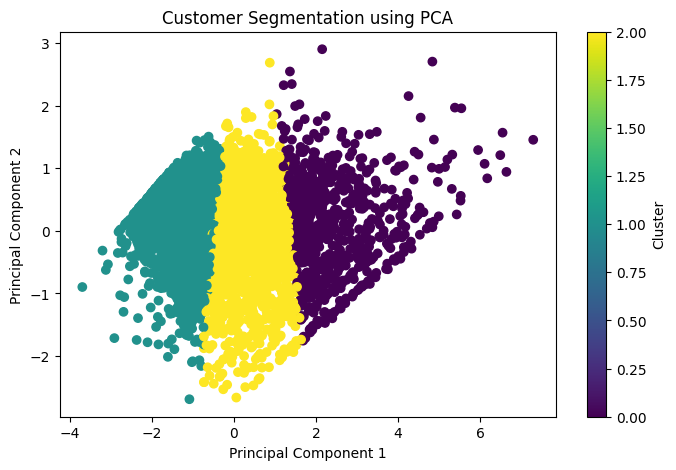

Explained Variance: [0.75102042 0.18759201]


In [ ]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

pca = PCA(n_components=2)

pca_data = pca.fit_transform(scaled_data)

plt.figure(figsize=(8, 5))

plt.scatter(
    pca_data[:, 0],
    pca_data[:, 1],
    c=rfm["KMeans_Cluster"],
    cmap="viridis"
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Customer Segmentation using PCA")
plt.colorbar(label="Cluster")
plt.show()

print("Explained Variance:", pca.explained_variance_ratio_)

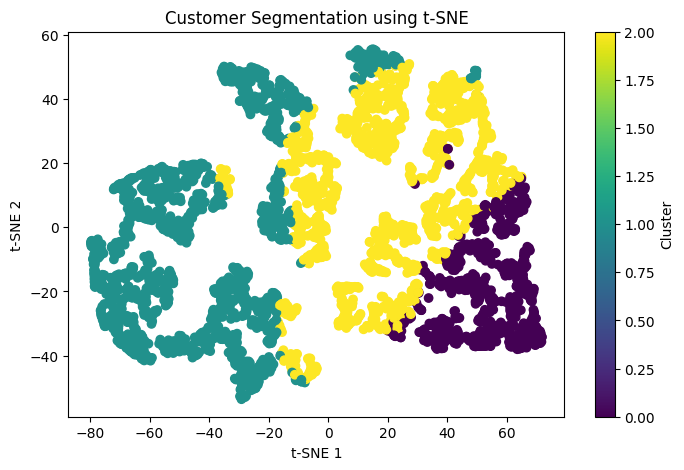

In [ ]:
from sklearn.manifold import TSNE

tsne = TSNE(
    n_components=2,
    random_state=42,
    perplexity=30
)

tsne_data = tsne.fit_transform(scaled_data)

plt.figure(figsize=(8, 5))

plt.scatter(
    tsne_data[:, 0],
    tsne_data[:, 1],
    c=rfm["KMeans_Cluster"],
    cmap="viridis"
)

plt.title("Customer Segmentation using t-SNE")
plt.xlabel("t-SNE 1")
plt.ylabel("t-SNE 2")
plt.colorbar(label="Cluster")
plt.show()

In [ ]:
cluster_summary = rfm.groupby("KMeans_Cluster").agg({
    "Recency": "mean",
    "Frequency": "mean",
    "Monetary": "mean"
}).round(2)

print(cluster_summary)

# Rank clusters by average monetary value
ranked = cluster_summary["Monetary"].sort_values(ascending=False)

personas = {}

for rank, cluster in enumerate(ranked.index):
    if rank == 0:
        personas[cluster] = "High Value Customers"
    elif rank == 1:
        personas[cluster] = "Regular Customers"
    else:
        personas[cluster] = "Low Value Customers"

rfm["Customer_Persona"] = rfm["KMeans_Cluster"].map(personas)

print("\nCustomer Personas:")
print(rfm[["Recency", "Frequency", "Monetary",
           "Customer_Persona"]].head(10))

print("\nPersona Counts:")
print(rfm["Customer_Persona"].value_counts())

                Recency  Frequency  Monetary
KMeans_Cluster                              
0                 17.06      13.34   7905.44
1                167.36       1.35    362.54
2                 44.21       3.38   1265.06

Customer Personas:
            Recency  Frequency  Monetary      Customer_Persona
CustomerID                                                    
12346.0         326          1  77183.60     Regular Customers
12347.0           2          7   4310.00  High Value Customers
12348.0          75          4   1797.24     Regular Customers
12349.0          19          1   1757.55     Regular Customers
12350.0         310          1    334.40   Low Value Customers
12352.0          36          8   2506.04  High Value Customers
12353.0         204          1     89.00   Low Value Customers
12354.0         232          1   1079.40   Low Value Customers
12355.0         214          1    459.40   Low Value Customers
12356.0          23          3   2811.43     Regular Customers

In [ ]:
print("K-Means Clusters:")
print(rfm["KMeans_Cluster"].value_counts())

print("\nDBSCAN Clusters:")
print(rfm["DBSCAN_Cluster"].value_counts())

print("\nK-Means Silhouette Score:",
      silhouette_score(scaled_data, rfm["KMeans_Cluster"]))

K-Means Clusters:
KMeans_Cluster
1    1872
2    1696
0     770
Name: count, dtype: int64

DBSCAN Clusters:
DBSCAN_Cluster
 0    4317
-1      21
Name: count, dtype: int64

K-Means Silhouette Score: 0.33650963406696927
